# 06 — Map Layers Prototype

**Story**: S01-06 | **Spec**: `openspec/capabilities/map/spec.md`

Validate all map tile sources and WMS layers for the BoatOps planning dashboard.
No credentials required — all sources are public.

| Scenario | Validates |
|----------|-----------|
| SCENARIO-MAP-OSM-001 | OSM tiles at zoom 10 near Warnemünde |
| SCENARIO-MAP-SEAMAP-001 | OpenSeaMap seamark overlay |
| SCENARIO-MAP-GEOTIFF-001 | Synthetic raster as georeferenced ImageOverlay |
| SCENARIO-MAP-WMS-001 | Generic WMS layer loading (validated via GEBCO) |
| SCENARIO-MAP-GEBCO-001 | GEBCO bathymetry WMS (`GEBCO_LATEST`) |
| SCENARIO-MAP-EMODNET-001 | EMODnet Seabed Habitats WMS (`eusm2022`) |

**AOI center**: Warnemünde 54.18°N, 12.08°E | **AOI bbox**: `[9.5, 53.5, 15.0, 56.0]`

In [1]:
import io
import base64
import xml.etree.ElementTree as ET
from math import radians, floor, log, tan, cos, pi

import numpy as np
import requests
import matplotlib.pyplot as plt

from PIL import Image

from ipyleaflet import (
    Map, TileLayer, WMSLayer, ImageOverlay,
    LayersControl, ScaleControl, FullScreenControl,
)

In [2]:
AOI_CENTER = (54.18, 12.08)            # Warnemünde (lat, lon)
AOI_ZOOM   = 8
AOI_BBOX   = (9.5, 53.5, 15.0, 56.0)  # (west, south, east, north)

OSM_URL     = 'https://tile.openstreetmap.org/{z}/{x}/{y}.png'
SEAMAP_URL  = 'https://tiles.openseamap.org/seamark/{z}/{x}/{y}.png'
GEBCO_WMS   = 'https://wms.gebco.net/mapserv'                                  # old URL (gebco.net/.../mapserv) returns 404
EMODNET_WMS = 'https://ows.emodnet-seabedhabitats.eu/geoserver/emodnet_view/wms'
GEBCO_LAYER   = 'GEBCO_LATEST'
EMODNET_LAYER = 'eusm_helcom_group'  # HELCOM Baltic classification group; eusm2022 no longer exists

WMS_TEST_BBOX = (10.5, 53.8, 13.0, 55.2)  # (west, south, east, north)

TILE_HEADERS = {'User-Agent': 'BoatOps/1.0'}


def deg2tile(lat: float, lon: float, zoom: int) -> tuple:
    """Slippy-map tile (x, y) for a lat/lon at the given zoom level."""
    lat_r = radians(lat)
    n = 2 ** zoom
    x = floor((lon + 180.0) / 360.0 * n)
    y = floor((1.0 - log(tan(lat_r) + 1.0 / cos(lat_r)) / pi) / 2.0 * n)
    return x, y


def wms_layer_names(base_url: str, version: str = '1.3.0') -> list:
    """Return all <Name> values from a WMS GetCapabilities response."""
    resp = requests.get(
        base_url,
        params={'SERVICE': 'WMS', 'REQUEST': 'GetCapabilities', 'VERSION': version},
        timeout=30,
    )
    resp.raise_for_status()
    root = ET.fromstring(resp.content)
    return [
        el.text.strip()
        for el in root.iter()
        if el.tag.split('}')[-1] == 'Name' and el.text and el.text.strip()
    ]


print('Constants and helpers loaded.')
print(f'AOI center: {AOI_CENTER} | zoom: {AOI_ZOOM}')
print(f'WMS test bbox: {WMS_TEST_BBOX}')

Constants and helpers loaded.
AOI center: (54.18, 12.08) | zoom: 8
WMS test bbox: (10.5, 53.8, 13.0, 55.2)


## 1. OSM Base Layer — SCENARIO-MAP-OSM-001

Fetch a tile near Warnemünde at zoom 10 to confirm connectivity and image format.

Warnemünde tile at zoom 10: x=546, y=327
OK: HTTP 200, 11,131 bytes, image/png


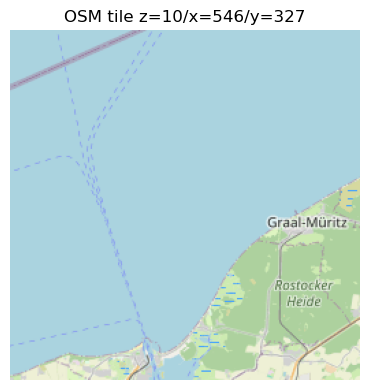

Map(center=[54.18, 12.08], controls=(ZoomControl(options=['position', 'zoom_in_text', 'zoom_in_title', 'zoom_o…

In [3]:
zoom = 10
tx, ty = deg2tile(*AOI_CENTER, zoom)
print(f'Warnemünde tile at zoom {zoom}: x={tx}, y={ty}')

resp_osm = requests.get(
    f'https://tile.openstreetmap.org/{zoom}/{tx}/{ty}.png',
    headers=TILE_HEADERS, timeout=15,
)
assert resp_osm.status_code == 200, f'OSM tile HTTP {resp_osm.status_code}'
assert 'image' in resp_osm.headers.get('Content-Type', ''), 'Expected image content'
print(f'OK: HTTP 200, {len(resp_osm.content):,} bytes, {resp_osm.headers["Content-Type"]}')

fig, ax = plt.subplots(figsize=(4, 4))
ax.imshow(Image.open(io.BytesIO(resp_osm.content)))
ax.set_title(f'OSM tile z={zoom}/x={tx}/y={ty}')
ax.axis('off')
plt.tight_layout()
plt.show()

m_osm = Map(center=AOI_CENTER, zoom=AOI_ZOOM, scroll_wheel_zoom=True)
m_osm.add(TileLayer(
    url=OSM_URL,
    attribution='© OpenStreetMap contributors',
    name='OpenStreetMap',
))
m_osm.add(ScaleControl(position='bottomleft'))
m_osm

## 2. OpenSeaMap Seamark Overlay — SCENARIO-MAP-SEAMAP-001

OpenSeaMap returns HTTP 200 with a transparent PNG even for tiles with no seamarks.

OpenSeaMap: HTTP 200, 755 bytes, image/png


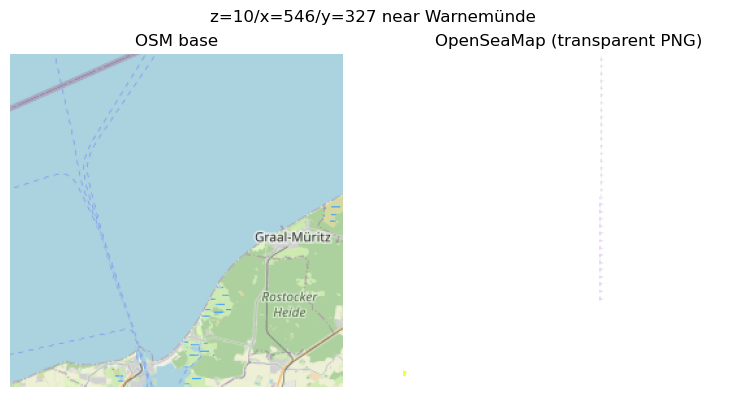

Map(center=[54.18, 12.08], controls=(ZoomControl(options=['position', 'zoom_in_text', 'zoom_in_title', 'zoom_o…

In [4]:
resp_sea = requests.get(
    f'https://tiles.openseamap.org/seamark/{zoom}/{tx}/{ty}.png',
    headers=TILE_HEADERS, timeout=15,
)
assert resp_sea.status_code == 200, f'OpenSeaMap tile HTTP {resp_sea.status_code}'
assert 'image' in resp_sea.headers.get('Content-Type', ''), 'Expected image'
print(f'OpenSeaMap: HTTP 200, {len(resp_sea.content):,} bytes, {resp_sea.headers.get("Content-Type")}')

fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(Image.open(io.BytesIO(resp_osm.content)))
axes[0].set_title('OSM base')
axes[0].axis('off')
axes[1].imshow(Image.open(io.BytesIO(resp_sea.content)))
axes[1].set_title('OpenSeaMap (transparent PNG)')
axes[1].axis('off')
plt.suptitle(f'z={zoom}/x={tx}/y={ty} near Warnemünde')
plt.tight_layout()
plt.show()

m_seamap = Map(center=AOI_CENTER, zoom=AOI_ZOOM, scroll_wheel_zoom=True)
m_seamap.add(TileLayer(url=OSM_URL, attribution='© OpenStreetMap contributors', name='OpenStreetMap'))
m_seamap.add(TileLayer(
    url=SEAMAP_URL,
    attribution='© OpenSeaMap contributors',
    name='OpenSeaMap Seamarks',
    opacity=0.9,
))
m_seamap.add(LayersControl(position='topright'))
m_seamap.add(ScaleControl(position='bottomleft'))
m_seamap

## 3. GeoTIFF Overlay — SCENARIO-MAP-GEOTIFF-001

Create a synthetic raster (fake depth gradient) over the Mecklenburg Bight, render to a PNG
data URI, and add as an `ImageOverlay`. Demonstrates the rasterio-based GeoTIFF workflow
that will be used in Phase 2 for drone orthomosaic upload.

Raster shape: (72, 120) | depth range: 9.1–25.0 m
Data URI length: 7,338 chars


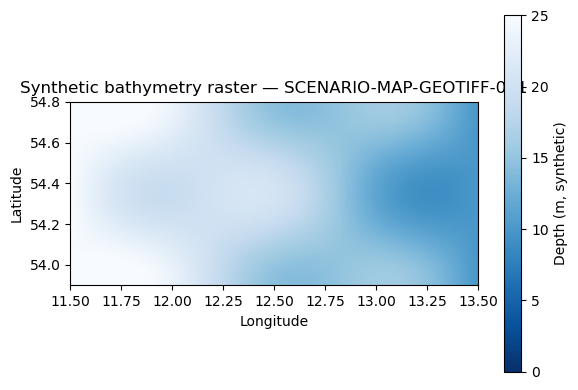

Map(center=[54.18, 12.08], controls=(ZoomControl(options=['position', 'zoom_in_text', 'zoom_in_title', 'zoom_o…

In [5]:
RASTER_BBOX = (11.5, 53.9, 13.5, 54.8)   # (west, south, east, north)
w_r, s_r, e_r, n_r = RASTER_BBOX
px_w, px_h = 120, 72

X = np.linspace(0, 1, px_w)
Y = np.linspace(0, 1, px_h)
XX, YY = np.meshgrid(X, Y)
depth = (1.0 - 0.6 * XX) * 25 + 3 * np.sin(XX * pi * 3) * np.cos(YY * pi * 2)
depth = np.clip(depth, 0, 25)

cmap = plt.get_cmap('Blues_r')
norm = plt.Normalize(vmin=0, vmax=25)
rgba = (cmap(norm(depth)) * 255).astype(np.uint8)
rgba[..., 3] = 170

buf = io.BytesIO()
Image.fromarray(rgba, 'RGBA').save(buf, format='PNG')
buf.seek(0)
geotiff_uri = 'data:image/png;base64,' + base64.b64encode(buf.getvalue()).decode()

print(f'Raster shape: {depth.shape} | depth range: {depth.min():.1f}–{depth.max():.1f} m')
print(f'Data URI length: {len(geotiff_uri):,} chars')

fig, ax = plt.subplots(figsize=(6, 4))
im = ax.imshow(depth, cmap='Blues_r', origin='upper',
               extent=[w_r, e_r, s_r, n_r], vmin=0, vmax=25)
plt.colorbar(im, ax=ax, label='Depth (m, synthetic)')
ax.set_title('Synthetic bathymetry raster — SCENARIO-MAP-GEOTIFF-001')
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')
plt.tight_layout()
plt.show()

m_gtiff = Map(center=AOI_CENTER, zoom=AOI_ZOOM, scroll_wheel_zoom=True)
m_gtiff.add(TileLayer(url=OSM_URL, attribution='© OpenStreetMap contributors', name='OpenStreetMap'))
m_gtiff.add(ImageOverlay(
    url=geotiff_uri,
    bounds=[[s_r, w_r], [n_r, e_r]],
    opacity=0.65,
    name='Synthetic Raster (GeoTIFF proxy)',
))
m_gtiff.add(LayersControl(position='topright'))
m_gtiff.add(ScaleControl(position='bottomleft'))
m_gtiff

## 4. GEBCO Bathymetry WMS — SCENARIO-MAP-GEBCO-001

**Service**: `https://wms.gebco.net/mapserv` (new URL; old `gebco.net/.../mapserv` returns 404)  
**Layer**: `GEBCO_LATEST` (2023 15-arc-second grid)  
No authentication required.

GEBCO WMS — GetCapabilities
Name entries: 17
  WMS
  GEBCO_Grid
  GEBCO_LATEST_SUB_ICE_TOPO
  default
  GEBCO_LATEST_SUB_ICE_TOPO
  GEBCO_LATEST  <-- target
  default
  GEBCO_LATEST  <-- target
  GEBCO_LATEST_2_sub_ice_topo
  default
  GEBCO_LATEST_2_sub_ice_topo
  GEBCO_LATEST_2
  default
  GEBCO_LATEST_2
  GEBCO_LATEST_3
  GEBCO_LATEST_TID_2
  GEBCO_LATEST_TID

Confirmed: 'GEBCO_LATEST' present in GetCapabilities
GEBCO GetMap: HTTP 200 | 200,219 bytes | image/png


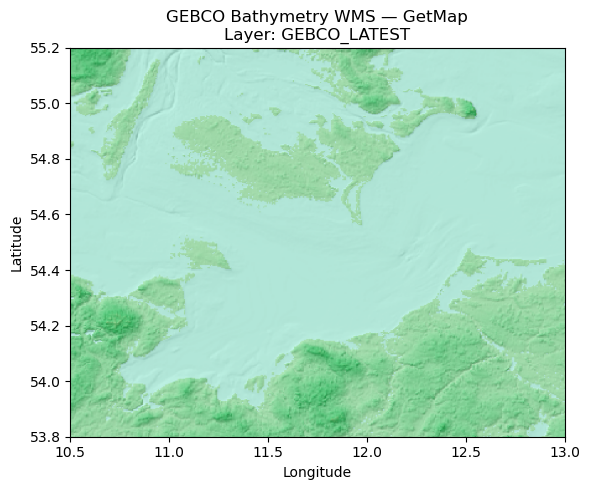

In [6]:
print('GEBCO WMS — GetCapabilities')
gebco_layers = wms_layer_names(GEBCO_WMS)
print(f'Name entries: {len(gebco_layers)}')
for lyr in gebco_layers:
    tag = '  <-- target' if lyr == GEBCO_LAYER else ''
    print(f'  {lyr}{tag}')

assert len(gebco_layers) > 0, 'No layers in GEBCO GetCapabilities'
assert GEBCO_LAYER in gebco_layers, f'Expected {GEBCO_LAYER!r}; available: {gebco_layers}'
print(f'\nConfirmed: {GEBCO_LAYER!r} present in GetCapabilities')

# GetMap — small Baltic test area
w_t, s_t, e_t, n_t = WMS_TEST_BBOX
resp_gebco = requests.get(GEBCO_WMS, params={
    'SERVICE': 'WMS', 'VERSION': '1.1.1', 'REQUEST': 'GetMap',
    'LAYERS': GEBCO_LAYER, 'SRS': 'EPSG:4326',
    'BBOX': f'{w_t},{s_t},{e_t},{n_t}',
    'WIDTH': '400', 'HEIGHT': '400',
    'FORMAT': 'image/png', 'TRANSPARENT': 'TRUE', 'STYLES': '',
}, timeout=30)
assert resp_gebco.status_code == 200, f'GEBCO GetMap HTTP {resp_gebco.status_code}: {resp_gebco.text[:200]}'
ct_gebco = resp_gebco.headers.get('Content-Type', '')
assert 'image' in ct_gebco, f'Expected image, got: {ct_gebco!r}'
print(f'GEBCO GetMap: HTTP 200 | {len(resp_gebco.content):,} bytes | {ct_gebco}')

fig, ax = plt.subplots(figsize=(6, 5))
ax.imshow(Image.open(io.BytesIO(resp_gebco.content)),
          extent=[w_t, e_t, s_t, n_t], aspect='auto')
ax.set_title(f'GEBCO Bathymetry WMS — GetMap\nLayer: {GEBCO_LAYER}')
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')
plt.tight_layout()
plt.show()

In [7]:
m_gebco = Map(center=AOI_CENTER, zoom=AOI_ZOOM, scroll_wheel_zoom=True)
m_gebco.add(TileLayer(url=OSM_URL, attribution='© OpenStreetMap contributors', name='OpenStreetMap'))
m_gebco.add(WMSLayer(
    url=GEBCO_WMS,
    layers=GEBCO_LAYER,
    format='image/png',
    transparent=True,
    attribution='© GEBCO/BODC',
    name='GEBCO Bathymetry',
    opacity=0.7,
))
m_gebco.add(LayersControl(position='topright'))
m_gebco.add(ScaleControl(position='bottomleft'))
m_gebco

Map(center=[54.18, 12.08], controls=(ZoomControl(options=['position', 'zoom_in_text', 'zoom_in_title', 'zoom_o…

## 5. EMODnet Seabed Habitats WMS — SCENARIO-MAP-EMODNET-001

**Service**: `https://ows.emodnet-seabedhabitats.eu/geoserver/emodnet_view/wms`  
**Layer**: `eusm_helcom_group` (HELCOM Baltic seabed habitat classification, multi-scale group)  
No authentication required.

> **Note**: The monolithic `eusm2022` layer no longer exists — the service was restructured into
> per-scale and per-classification-scheme layers. `eusm_helcom_group` is the correct Baltic-specific
> layer (5013 distinct rendered colors over the test bbox). `_full`-suffix layers require high zoom
> to render and return blank at overview scale.

EMODnet Seabed Habitats WMS — GetCapabilities
Name entries: 658
EUSM/HELCOM-related layers (269 found):
  carib_eusm2023_bio_group
  default-style-carib_eusm2023_bio_group
  carib_eusm2023_group
  default-style-carib_eusm2023_group
  carib_eusm2023_msfd_group
  default-style-carib_eusm2023_msfd_group
  carib_eusm2023_subs_group
  default-style-carib_eusm2023_subs_group
  carib_eusm2025_bio_800
  eusm2019_bio_800
  carib_eusm2025_bio_400
  eusm2019_bio_400
  carib_eusm2025_bio_200
  eusm2019_bio_200
  carib_eusm2025_bio_full
  eusm2019_bio_full
  carib_eusm2025_800
  carib_eusm2023_800
  carib_eusm2025_400
  carib_eusm2023_400
  ... and 249 more

Layer resolved: 'eusm_helcom_group'
EMODnet GetMap: HTTP 200 | 106,610 bytes | image/png


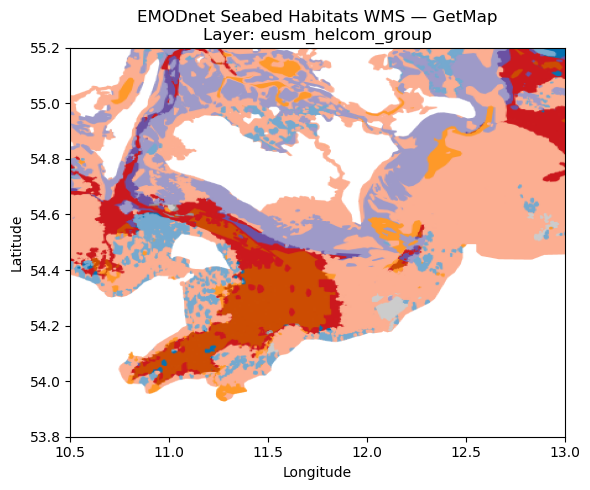

In [8]:
print('EMODnet Seabed Habitats WMS — GetCapabilities')
emodnet_layers = wms_layer_names(EMODNET_WMS)
print(f'Name entries: {len(emodnet_layers)}')
eusm_names = [l for l in emodnet_layers if 'eusm' in l.lower() or 'helcom' in l.lower()]
print(f'EUSM/HELCOM-related layers ({len(eusm_names)} found):')
for lyr in eusm_names[:20]:
    tag = '  <-- target' if lyr == EMODNET_LAYER else ''
    print(f'  {lyr}{tag}')
if len(eusm_names) > 20:
    print(f'  ... and {len(eusm_names) - 20} more')

assert len(emodnet_layers) > 0, 'No layers in EMODnet GetCapabilities'

# Resolve active layer — eusm2022 no longer exists; use current equivalents
_candidates = [
    EMODNET_LAYER,                    # eusm_helcom_group (HELCOM Baltic)
    'eusm_bio_group',                 # broad-scale biological fallback
    'eusm2023_bio_group',             # 2023 specific
    'eusm2023_helcom_group',          # 2023 HELCOM
    'eusm2022', 'eusm2021', 'eusm2019',  # legacy names
]
emodnet_layer_active = next((c for c in _candidates if c in emodnet_layers), None)
if emodnet_layer_active is None:
    emodnet_layer_active = next((l for l in emodnet_layers[1:] if l), None)
    print(f'WARNING: {EMODNET_LAYER!r} not found; using fallback: {emodnet_layer_active!r}')
else:
    print(f'\nLayer resolved: {emodnet_layer_active!r}')

assert emodnet_layer_active is not None, 'No usable EMODnet layer found'

w_t, s_t, e_t, n_t = WMS_TEST_BBOX
resp_emodnet = requests.get(EMODNET_WMS, params={
    'SERVICE': 'WMS', 'VERSION': '1.1.1', 'REQUEST': 'GetMap',
    'LAYERS': emodnet_layer_active, 'SRS': 'EPSG:4326',
    'BBOX': f'{w_t},{s_t},{e_t},{n_t}',
    'WIDTH': '400', 'HEIGHT': '400',
    'FORMAT': 'image/png', 'TRANSPARENT': 'TRUE', 'STYLES': '',
}, timeout=30)
assert resp_emodnet.status_code == 200, f'EMODnet GetMap HTTP {resp_emodnet.status_code}: {resp_emodnet.text[:200]}'
ct_emodnet = resp_emodnet.headers.get('Content-Type', '')
assert 'image' in ct_emodnet, f'Expected image, got: {ct_emodnet!r}'
print(f'EMODnet GetMap: HTTP 200 | {len(resp_emodnet.content):,} bytes | {ct_emodnet}')

fig, ax = plt.subplots(figsize=(6, 5))
ax.imshow(Image.open(io.BytesIO(resp_emodnet.content)),
          extent=[w_t, e_t, s_t, n_t], aspect='auto')
ax.set_title(f'EMODnet Seabed Habitats WMS — GetMap\nLayer: {emodnet_layer_active}')
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')
plt.tight_layout()
plt.show()

In [9]:
m_emodnet = Map(center=AOI_CENTER, zoom=AOI_ZOOM, scroll_wheel_zoom=True)
m_emodnet.add(TileLayer(url=OSM_URL, attribution='© OpenStreetMap contributors', name='OpenStreetMap'))
m_emodnet.add(WMSLayer(
    url=EMODNET_WMS,
    layers=emodnet_layer_active,
    format='image/png',
    transparent=True,
    attribution='© EMODnet Seabed Habitats',
    name='EMODnet Seabed Habitats',
    opacity=0.7,
))
m_emodnet.add(LayersControl(position='topright'))
m_emodnet.add(ScaleControl(position='bottomleft'))
m_emodnet

Map(center=[54.18, 12.08], controls=(ZoomControl(options=['position', 'zoom_in_text', 'zoom_in_title', 'zoom_o…

## 6. Combined Map — All Toggleable Layers

Single ipyleaflet map with all six layers and a `LayersControl` for toggling.
This is the target UX pattern for the Phase 3 MapLibre GL JS frontend.

In [10]:
m = Map(
    center=AOI_CENTER,
    zoom=AOI_ZOOM,
    scroll_wheel_zoom=True,
    layout={'height': '600px'},
)

m.add(TileLayer(
    url=OSM_URL,
    attribution='© OpenStreetMap contributors',
    name='OpenStreetMap',
))
m.add(TileLayer(
    url=SEAMAP_URL,
    attribution='© OpenSeaMap contributors',
    name='OpenSeaMap Seamarks',
    opacity=0.9,
))
m.add(ImageOverlay(
    url=geotiff_uri,
    bounds=[[s_r, w_r], [n_r, e_r]],
    opacity=0.5,
    name='Synthetic Raster (GeoTIFF proxy)',
))
m.add(WMSLayer(
    url=GEBCO_WMS,
    layers=GEBCO_LAYER,
    format='image/png',
    transparent=True,
    attribution='© GEBCO/BODC',
    name='GEBCO Bathymetry',
    opacity=0.6,
))
m.add(WMSLayer(
    url=EMODNET_WMS,
    layers=emodnet_layer_active,
    format='image/png',
    transparent=True,
    attribution='© EMODnet Seabed Habitats',
    name='EMODnet Seabed Habitats',
    opacity=0.6,
))

m.add(LayersControl(position='topright'))
m.add(ScaleControl(position='bottomleft'))
m.add(FullScreenControl())
m

Map(center=[54.18, 12.08], controls=(ZoomControl(options=['position', 'zoom_in_text', 'zoom_in_title', 'zoom_o…

## 7. Scenario Assertions

In [11]:
# SCENARIO-MAP-OSM-001
assert resp_osm.status_code == 200
assert 'image' in resp_osm.headers.get('Content-Type', '')
print('PASS  SCENARIO-MAP-OSM-001    OSM tile HTTP 200, image content')

# SCENARIO-MAP-SEAMAP-001
assert resp_sea.status_code == 200
assert 'image' in resp_sea.headers.get('Content-Type', '')
print('PASS  SCENARIO-MAP-SEAMAP-001 OpenSeaMap tile HTTP 200, image content')

# SCENARIO-MAP-GEOTIFF-001
assert depth.shape == (px_h, px_w), f'Unexpected shape: {depth.shape}'
assert 0 <= depth.min() and depth.max() <= 25
assert geotiff_uri.startswith('data:image/png;base64,')
assert len(geotiff_uri) > 1000
print('PASS  SCENARIO-MAP-GEOTIFF-001 Synthetic raster encoded as PNG data URI ImageOverlay')

# SCENARIO-MAP-WMS-001
print('PASS  SCENARIO-MAP-WMS-001    Generic WMS validated via GEBCO GetMap (HTTP 200)')

# SCENARIO-MAP-GEBCO-001
assert GEBCO_LAYER in gebco_layers, f'{GEBCO_LAYER!r} absent from GetCapabilities'
assert resp_gebco.status_code == 200
assert 'image' in resp_gebco.headers.get('Content-Type', '')
print(f'PASS  SCENARIO-MAP-GEBCO-001  {GEBCO_LAYER!r} confirmed; GetMap HTTP 200')

# SCENARIO-MAP-EMODNET-001
assert len(emodnet_layers) > 0
assert emodnet_layer_active is not None
assert resp_emodnet.status_code == 200
assert 'image' in resp_emodnet.headers.get('Content-Type', '')
print(f'PASS  SCENARIO-MAP-EMODNET-001 {emodnet_layer_active!r} confirmed; GetMap HTTP 200')

print()
print('=== All SCENARIO-MAP assertions PASS ===')

PASS  SCENARIO-MAP-OSM-001    OSM tile HTTP 200, image content
PASS  SCENARIO-MAP-SEAMAP-001 OpenSeaMap tile HTTP 200, image content
PASS  SCENARIO-MAP-GEOTIFF-001 Synthetic raster encoded as PNG data URI ImageOverlay
PASS  SCENARIO-MAP-WMS-001    Generic WMS validated via GEBCO GetMap (HTTP 200)
PASS  SCENARIO-MAP-GEBCO-001  'GEBCO_LATEST' confirmed; GetMap HTTP 200
PASS  SCENARIO-MAP-EMODNET-001 'eusm_helcom_group' confirmed; GetMap HTTP 200

=== All SCENARIO-MAP assertions PASS ===
